# 45. How much bandwidth does a rocket launch need? Sampling rate and sensor corner frequency

Two network-design questions, answered with the Artemis II recordings:

1. **Sampling rate.** The Centaurs (Trillium Compact, infraBSU) and SmartSolos recorded at 500 sps;
   the Gems at 100 sps. What fraction of the launch signal lies above the Nyquist frequency of
   250, 200 and 100 sps, and how much do peak amplitude and energy change after resampling?
2. **Low-frequency corner.** The Trillium Compact is flat to ~0.008 Hz (120 s), a SmartSolo geophone
   rolls off below ~5 Hz, and a traditional short-period sensor below ~0.5-1 Hz. What fraction of the
   launch signal lies below those corners, and is it rocket signal or background noise (microseisms)?

**Rocket signal** is measured as *excess* power: the PSD of the 300-s launch window minus the PSD of
an equal-length pre-launch noise window (negative values set to zero). Fractions are of the excess
energy integrated over the full band.

Sensors are simulated by passing the broadband velocity through a two-pole velocity-sensor response
$H(s)=s^2/(s^2+2h\omega_0 s+\omega_0^2)$ (damping $h$), equivalent to an ideal geophone or short-period
seismometer normalized to 1 at high frequency.

Responses: Centaur StationXML valid at launch (`cfg.centaur_inventory`), with the infraBSU stage
(46 µV/Pa) added to the CD channels. B29 CHZ comes from the restored launch-window file.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import welch, csd
from obspy import Stream

import artemis2_config as cfg

L = cfg.LAUNCHTIME
SIGNAL = (cfg.STARTTRIM, cfg.ENDTRIM)    # 300 s launch window
NOISE = (L - 900, L - 600)               # 300 s pre-launch background
NPERSEG = 2 ** 15                        # 65.5 s Welch segments at 500 sps
LOW_CUTS = (0.5, 1.0, 5.0)               # Hz: candidate low-frequency corners
RATES = (250, 200, 100)                  # sps: candidate sampling rates
PASSBAND = 0.8                           # usable fraction of Nyquist after anti-alias filtering

SEISMIC = ['1R.B01.00.CHZ', '1R.B05.00.CHZ', '1R.B29.00.CHZ']
INFRA = ['1R.B01.00.CD0', '1R.B05.00.CD0', '1R.B29.00.CD0']
DIST_KM = {'B01': 1.53, 'B05': 2.75, 'B29': 5.57}
COLORS = {'B01': '#2a78d6', 'B05': '#eb6834', 'B29': '#1baf7a'}   # categorical slots 1-3

plt.rcParams.update({'axes.grid': True, 'grid.color': '#dddddd', 'grid.linewidth': 0.6,
                     'axes.spines.top': False, 'axes.spines.right': False, 'lines.linewidth': 1.0})
OUT = cfg.OUT_DIR / "45_sampling_rate_and_bandwidth"
OUT.mkdir(parents=True, exist_ok=True)
print('output:', OUT)

output: /Users/glennthompson/Library/CloudStorage/Box-Box/thompsong/3_Project_Documents/NASAprojects/201602_Rocket_Seismology/writing/Artemis2/45_sampling_rate_and_bandwidth


## 1. Load and correct to ground velocity (m/s) and pressure (Pa)

In [2]:
client = cfg.sds_client()

def load(seed_id):
    net, sta, loc, cha = seed_id.split('.')
    st = cfg.read_channel(seed_id, client=client)   # D?? or C?? archive; B29 CHZ from the restored copy
    st.merge(fill_value=0)
    tr = st[0]
    nyq = 0.5 * tr.stats.sampling_rate
    tr.detrend('linear')
    tr.remove_response(inventory=cfg.centaur_inventory(sta),
                       output='VEL' if cha.startswith('CH') else 'DEF',
                       pre_filt=(0.002, 0.004, 0.9 * nyq, 0.95 * nyq), taper=True, zero_mean=True)
    return tr

data = Stream([load(sid) for sid in SEISMIC + INFRA])
for tr in data:
    s = tr.slice(*SIGNAL)
    unit = 'm/s' if tr.stats.channel.startswith('CH') else 'Pa'
    print(f'{tr.id}: {tr.stats.sampling_rate:.0f} sps, peak {np.abs(s.data).max():.3g} {unit}')

/opt/anaconda3/envs/flovopy_plus/lib/python3.12/site-packages/obspy/core/inventory/response.py:1089: UserWarning: ObsPy can not map unit 'Pa' to displacement, velocity, or acceleration - evalresp should still work and just use the response as is. This might not be covered by tests, though, so proceed with caution and report any unexpected behavior.
  warnings.warn(msg)


/opt/anaconda3/envs/flovopy_plus/lib/python3.12/site-packages/obspy/core/inventory/response.py:1089: UserWarning: ObsPy can not map unit 'Pa' to displacement, velocity, or acceleration - evalresp should still work and just use the response as is. This might not be covered by tests, though, so proceed with caution and report any unexpected behavior.
  warnings.warn(msg)


/opt/anaconda3/envs/flovopy_plus/lib/python3.12/site-packages/obspy/core/inventory/response.py:1089: UserWarning: ObsPy can not map unit 'Pa' to displacement, velocity, or acceleration - evalresp should still work and just use the response as is. This might not be covered by tests, though, so proceed with caution and report any unexpected behavior.
  warnings.warn(msg)


/opt/anaconda3/envs/flovopy_plus/lib/python3.12/site-packages/obspy/core/inventory/response.py:1089: UserWarning: ObsPy can not map unit 'Pa' to displacement, velocity, or acceleration - evalresp should still work and just use the response as is. This might not be covered by tests, though, so proceed with caution and report any unexpected behavior.
  warnings.warn(msg)


/opt/anaconda3/envs/flovopy_plus/lib/python3.12/site-packages/obspy/core/inventory/response.py:1089: UserWarning: ObsPy can not map unit 'Pa' to displacement, velocity, or acceleration - evalresp should still work and just use the response as is. This might not be covered by tests, though, so proceed with caution and report any unexpected behavior.
  warnings.warn(msg)


/opt/anaconda3/envs/flovopy_plus/lib/python3.12/site-packages/obspy/core/inventory/response.py:1089: UserWarning: ObsPy can not map unit 'Pa' to displacement, velocity, or acceleration - evalresp should still work and just use the response as is. This might not be covered by tests, though, so proceed with caution and report any unexpected behavior.
  warnings.warn(msg)


1R.B01.00.CHZ: 500 sps, peak 0.00294 m/s
1R.B05.00.CHZ: 500 sps, peak 0.00288 m/s
1R.B29.00.CHZ: 500 sps, peak 0.000987 m/s
1R.B01.00.CD0: 500 sps, peak 510 Pa
1R.B05.00.CD0: 500 sps, peak 343 Pa
1R.B29.00.CD0: 500 sps, peak 111 Pa


## 2. Launch and background spectra

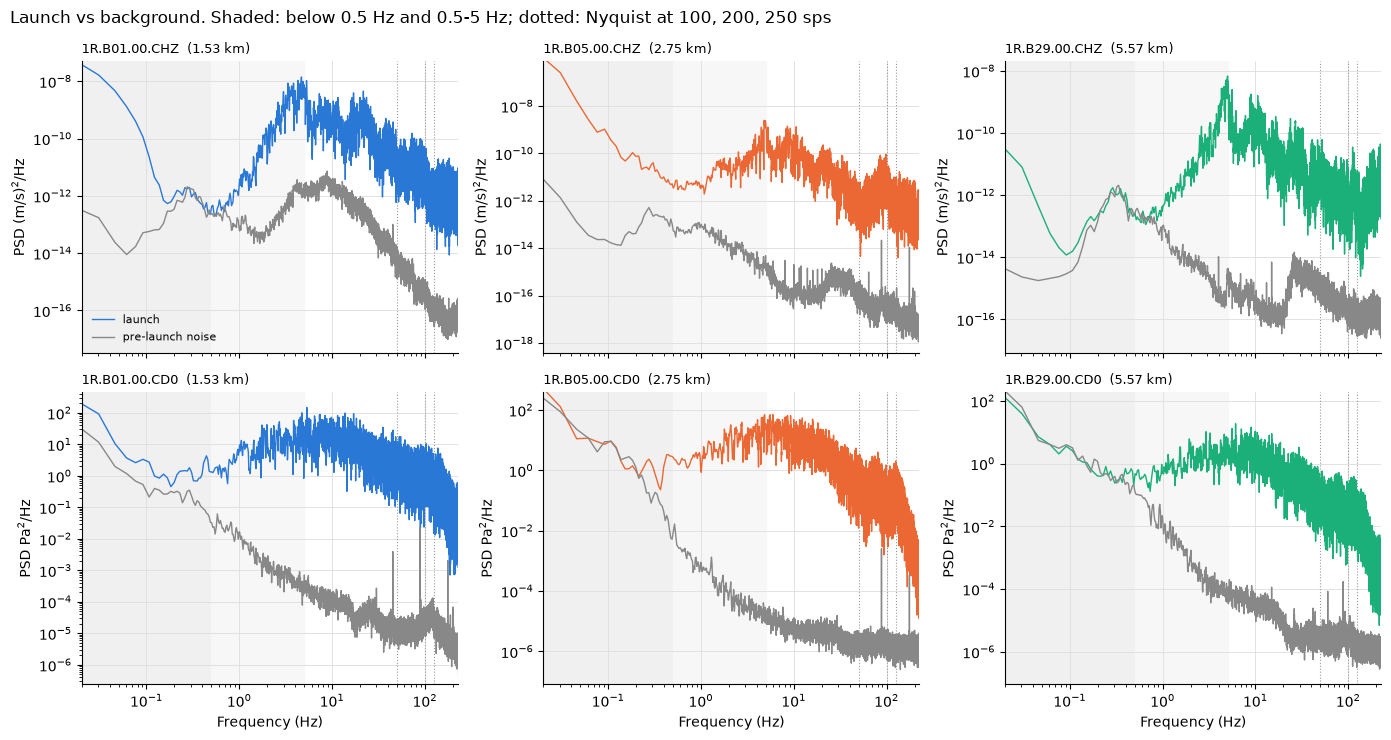

In [3]:
FMAX = 225.0   # Hz: top of the Centaur anti-alias passband at 500 sps

def psd(tr, window):
    x = tr.slice(*window).data.astype(float)
    x = x - x.mean()
    return welch(x, tr.stats.sampling_rate, nperseg=NPERSEG)

spec = {}
for tr in data:
    f, ps = psd(tr, SIGNAL)
    _, pn = psd(tr, NOISE)
    spec[tr.id] = dict(f=f, sig=ps, noise=pn, excess=np.clip(ps - pn, 0, None))

def shade(ax):
    ax.axvspan(1e-3, 0.5, color='#f0f0f0', zorder=0)
    ax.axvspan(0.5, 5.0, color='#f7f7f7', zorder=0)
    for fr in (50, 100, 125):
        ax.axvline(fr, color='#999999', lw=0.8, ls=':')

fig, axes = plt.subplots(2, 3, figsize=(14, 7.5), sharex=True)
for row, ids, unit in ((0, SEISMIC, '(m/s)$^2$/Hz'), (1, INFRA, 'Pa$^2$/Hz')):
    for col, sid in enumerate(ids):
        ax = axes[row, col]; s = spec[sid]; sta = sid.split('.')[1]; m = s['f'] > 0
        shade(ax)
        ax.loglog(s['f'][m], s['sig'][m], color=COLORS[sta], label='launch')
        ax.loglog(s['f'][m], s['noise'][m], color='#888888', label='pre-launch noise')
        ax.set_title(f'{sid}  ({DIST_KM[sta]} km)', fontsize=9, loc='left')
        ax.set_ylabel(f'PSD {unit}')
        ax.set_xlim(0.02, FMAX)
        inband = (s['f'] >= 0.02) & (s['f'] <= FMAX)
        vals = np.r_[s['sig'][inband], s['noise'][inband]]
        vals = vals[vals > 0]
        ax.set_ylim(vals.min() / 3, vals.max() * 3)
axes[0, 0].legend(frameon=False, fontsize=8)
for ax in axes[1]:
    ax.set_xlabel('Frequency (Hz)')
fig.suptitle('Launch vs background. Shaded: below 0.5 Hz and 0.5-5 Hz; dotted: Nyquist at 100, 200, 250 sps',
             x=0.01, ha='left')
fig.tight_layout()
fig.savefig(OUT / 'bandwidth_psd.png', dpi=200)

## 3. Fraction of rocket-signal energy lost by each design choice

In [4]:
def band_energy(f, p, lo=0.0, hi=np.inf):
    m = (f >= lo) & (f < hi)
    return np.trapezoid(p[m], f[m])

rows = []
for sid, s in spec.items():
    f = s['f']
    tot = band_energy(f, s['excess'])
    row = dict(seed_id=sid, distance_km=DIST_KM[sid.split('.')[1]],
               snr_energy=band_energy(f, s['sig']) / band_energy(f, s['noise']))
    for fc in LOW_CUTS:
        row[f'signal_below_{fc:g}Hz_%'] = 100 * band_energy(f, s['excess'], hi=fc) / tot
        row[f'noise_below_{fc:g}Hz_%'] = 100 * band_energy(f, s['noise'], hi=fc) / band_energy(f, s['noise'])
    for fs in RATES:
        row[f'signal_above_{fs}sps_nyq_%'] = 100 * band_energy(f, s['excess'], lo=fs / 2) / tot
        row[f'signal_above_{fs}sps_pass_%'] = 100 * band_energy(f, s['excess'], lo=PASSBAND * fs / 2) / tot
    rows.append(row)
fractions = pd.DataFrame(rows).set_index('seed_id')
fractions.to_csv(OUT / 'bandwidth_energy_fractions.csv')
with pd.option_context('display.float_format', '{:.2f}'.format, 'display.width', 250):
    display(fractions.T)

seed_id,1R.B01.00.CHZ,1R.B05.00.CHZ,1R.B29.00.CHZ,1R.B01.00.CD0,1R.B05.00.CD0,1R.B29.00.CD0
distance_km,1.53,2.75,5.57,1.53,2.75,5.57
snr_energy,945.65,85997.07,11704.34,532.16,38.54,7.06
signal_below_0.5Hz_%,5.55,92.74,0.02,0.91,3.41,0.15
noise_below_0.5Hz_%,0.95,81.18,48.15,98.12,99.98,99.63
signal_below_1Hz_%,5.55,92.74,0.02,1.09,3.73,0.49
noise_below_1Hz_%,1.27,87.06,65.45,99.02,99.99,99.94
signal_below_5Hz_%,39.00,94.41,35.73,10.63,18.91,14.45
noise_below_5Hz_%,11.56,96.34,71.83,99.52,99.99,99.99
signal_above_250sps_nyq_%,0.79,0.21,5.43,5.53,1.45,1.60
signal_above_250sps_pass_%,1.10,0.39,6.32,10.86,3.02,4.51


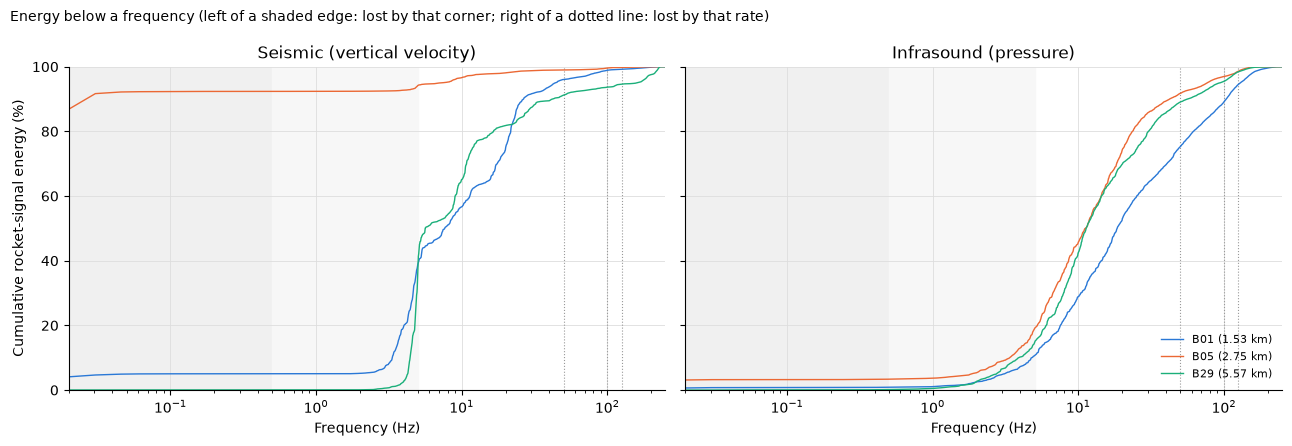

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, ids, title in ((axes[0], SEISMIC, 'Seismic (vertical velocity)'), (axes[1], INFRA, 'Infrasound (pressure)')):
    shade(ax)
    for sid in ids:
        s = spec[sid]; sta = sid.split('.')[1]; m = s['f'] > 0
        cum = np.cumsum(s['excess'][m] * np.gradient(s['f'][m]))
        ax.semilogx(s['f'][m], 100 * cum / cum[-1], color=COLORS[sta], label=f'{sta} ({DIST_KM[sta]} km)')
    ax.set(xlim=(0.02, 250), ylim=(0, 100), xlabel='Frequency (Hz)', title=title)
axes[0].set_ylabel('Cumulative rocket-signal energy (%)')
axes[1].legend(frameon=False, fontsize=8, loc='lower right')
fig.suptitle('Energy below a frequency (left of a shaded edge: lost by that corner; right of a dotted line: lost by that rate)',
             x=0.01, ha='left', fontsize=10)
fig.tight_layout()
fig.savefig(OUT / 'bandwidth_cumulative_energy.png', dpi=200)

## 4. Time domain: resampling and simulated sensors

Peak, RMS and energy in the launch window relative to the 500-sps broadband record. Resampling uses
`scipy.signal.resample_poly` (polyphase decimation with a Kaiser-window FIR anti-alias filter at the new
Nyquist), as a digitizer would; sensors use the two-pole response above, plus a 2-pole Butterworth
high-pass at the same corners for comparison.

In [6]:
def sensor_paz(f0, h):
    w0 = 2 * np.pi * f0
    roots = np.roots([1, 2 * h * w0, w0 ** 2])
    return {'poles': list(roots), 'zeros': [0j, 0j], 'gain': 1.0, 'sensitivity': 1.0}

VARIANTS = {f'resample {fs} sps': ('resample', fs) for fs in RATES}
VARIANTS.update({
    'short period 1 Hz (h=0.707)': ('sensor', (1.0, 0.707)),
    'short period 0.5 Hz (h=0.707)': ('sensor', (0.5, 0.707)),
    'geophone 5 Hz (h=0.7)': ('sensor', (5.0, 0.7)),
    'high-pass 0.5 Hz': ('highpass', 0.5),
    'high-pass 5 Hz': ('highpass', 5.0),
})

def variant(tr, how, arg):
    t = tr.copy()
    if how == 'resample':
        from fractions import Fraction
        from scipy.signal import resample_poly
        q = Fraction(int(arg), int(t.stats.sampling_rate))
        t.data = resample_poly(t.data.astype(float), q.numerator, q.denominator)
        t.stats.sampling_rate = float(arg)
    elif how == 'sensor':
        t.simulate(paz_remove=None, paz_simulate=sensor_paz(*arg), taper=False)
    else:
        t.filter('highpass', freq=arg, corners=2, zerophase=False)
    return t

def metrics(t):
    x = t.slice(*SIGNAL).data.astype(float)
    return np.abs(x).max(), np.sqrt(np.mean(x ** 2))

rows, versions = [], {}
for tr in data:
    peak0, rms0 = metrics(tr)
    for name, (how, arg) in VARIANTS.items():
        if how != 'resample' and not tr.stats.channel.startswith('CH'):
            continue                     # sensor simulations: seismic only
        t = variant(tr, how, arg)
        versions[(tr.id, name)] = t
        peak, rms = metrics(t)
        rows.append(dict(seed_id=tr.id, variant=name, peak_ratio=peak / peak0,
                         rms_ratio=rms / rms0, energy_ratio=(rms / rms0) ** 2))
td = pd.DataFrame(rows)
td.to_csv(OUT / 'bandwidth_time_domain.csv', index=False)
with pd.option_context('display.float_format', '{:.3f}'.format):
    display(td.pivot(index='variant', columns='seed_id', values='peak_ratio').round(3))
    display(td.pivot(index='variant', columns='seed_id', values='energy_ratio').round(3))

seed_id,1R.B01.00.CD0,1R.B01.00.CHZ,1R.B05.00.CD0,1R.B05.00.CHZ,1R.B29.00.CD0,1R.B29.00.CHZ
variant,,,,,,
geophone 5 Hz (h=0.7),NaN,0.876,NaN,0.412,NaN,0.863
high-pass 0.5 Hz,NaN,0.963,NaN,0.557,NaN,1.009
high-pass 5 Hz,NaN,0.873,NaN,0.412,NaN,0.857
resample 100 sps,0.565,0.828,0.949,1.003,0.932,0.918
resample 200 sps,0.772,0.861,0.954,0.993,1.022,0.965
resample 250 sps,0.807,0.968,0.989,0.976,0.962,0.983
short period 0.5 Hz (h=0.707),NaN,0.963,NaN,0.556,NaN,1.009
short period 1 Hz (h=0.707),NaN,0.928,NaN,0.537,NaN,1.000


seed_id,1R.B01.00.CD0,1R.B01.00.CHZ,1R.B05.00.CD0,1R.B05.00.CHZ,1R.B29.00.CD0,1R.B29.00.CHZ
variant,,,,,,
geophone 5 Hz (h=0.7),NaN,0.619,NaN,0.007,NaN,0.694
high-pass 0.5 Hz,NaN,0.852,NaN,0.009,NaN,0.998
high-pass 5 Hz,NaN,0.614,NaN,0.007,NaN,0.687
resample 100 sps,0.737,0.965,0.949,0.999,0.947,0.915
resample 200 sps,0.883,0.990,0.982,0.999,0.979,0.941
resample 250 sps,0.934,0.993,0.990,1.000,0.991,0.948
short period 0.5 Hz (h=0.707),NaN,0.852,NaN,0.009,NaN,0.998
short period 1 Hz (h=0.707),NaN,0.851,NaN,0.009,NaN,0.997


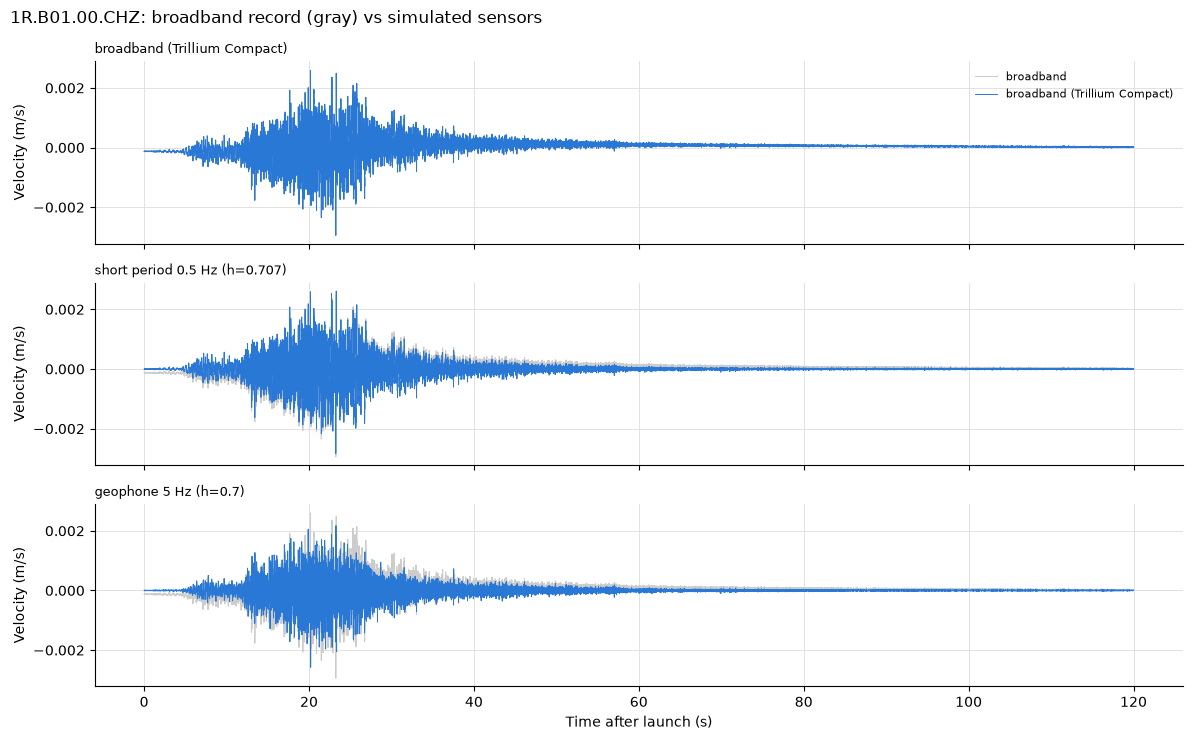

In [7]:
sid = '1R.B01.00.CHZ'
names = ['short period 0.5 Hz (h=0.707)', 'geophone 5 Hz (h=0.7)']
fig, axes = plt.subplots(3, 1, figsize=(12, 7.5), sharex=True, sharey=True)
base = data.select(id=sid)[0].slice(L, L + 120)
for ax, (label, t) in zip(axes, [('broadband (Trillium Compact)', base)] +
                          [(n, versions[(sid, n)].slice(L, L + 120)) for n in names]):
    ax.plot(base.times(), base.data, color='#cccccc', lw=0.8, label='broadband')
    ax.plot(t.times(), t.data, color='#2a78d6', lw=0.7, label=label)
    ax.set_ylabel('Velocity (m/s)')
    ax.set_title(label, fontsize=9, loc='left')
axes[-1].set_xlabel('Time after launch (s)')
axes[0].legend(frameon=False, fontsize=8, loc='upper right')
fig.suptitle(f'{sid}: broadband record (gray) vs simulated sensors', x=0.01, ha='left')
fig.tight_layout()
fig.savefig(OUT / 'bandwidth_simulated_sensors_B01.png', dpi=200)

## 5. SmartSolo vs Trillium Compact at B01

Harvested SmartSolo MiniSEED is geophone output in mV: the digitizer gain has been removed, but not
the geophone response. The transfer function SmartSolo/Trillium shows the plateau (≈ sensitivity in
mV per m/s) and the roll-off and 90° phase shift at the 5 Hz natural frequency.

median |H| 10-50 Hz: 74033 mV/(m/s)  (nominal 76700)
median phase 10-50 Hz: observed -150 deg, nominal 14 deg


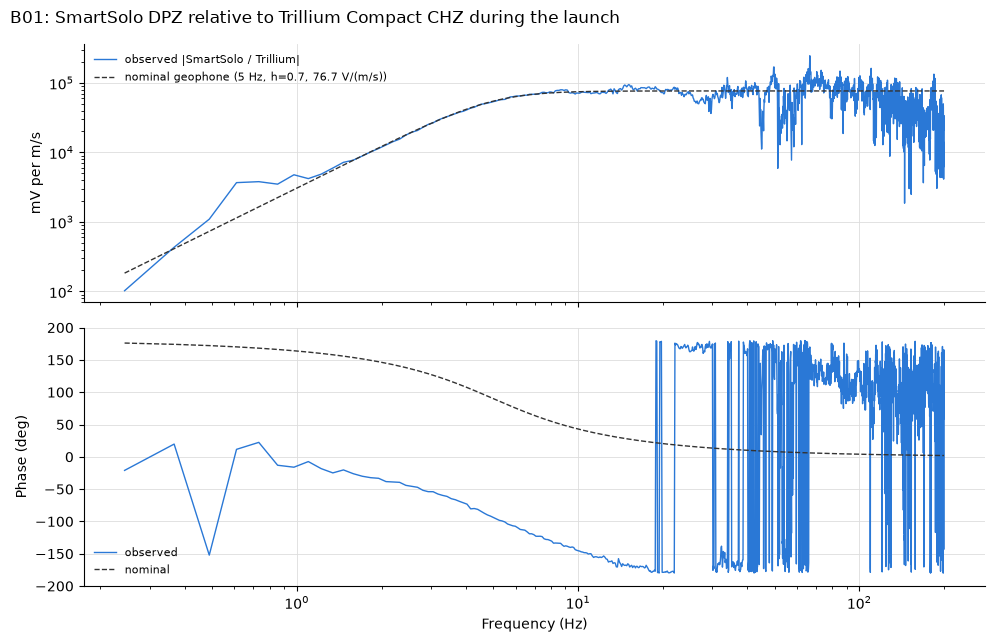

In [8]:
tz = data.select(id='1R.B01.00.CHZ')[0]
# SDS file names use '--' for the blank location code, so match it with '*'
ss = client.get_waveforms('1R', 'B01', '*', 'DPZ', cfg.STARTTIME, cfg.ENDTIME).merge(fill_value=0)[0]
ss.detrend('linear')
x = tz.slice(*SIGNAL).data.astype(float); y = ss.slice(*SIGNAL).data.astype(float)
n = min(len(x), len(y)); x, y = x[:n], y[:n]
f, pxy = csd(x, y, 500, nperseg=4096); _, pxx = welch(x, 500, nperseg=4096)
H = pxy / pxx
g = cfg.SMARTSOLO_GEOPHONE
w = 2j * np.pi * f
model = g['sensitivity_mV_per_mps'] * w ** 2 / (w ** 2 + 2 * g['damping'] * 2 * np.pi * g['f0'] * w + (2 * np.pi * g['f0']) ** 2)

fig, ax = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True)
m = (f > 0.2) & (f < 200)
ax[0].loglog(f[m], np.abs(H[m]), color='#2a78d6', label='observed |SmartSolo / Trillium|')
ax[0].loglog(f[m], np.abs(model[m]), color='#333333', ls='--', label='nominal geophone (5 Hz, h=0.7, 76.7 V/(m/s))')
ax[0].set_ylabel('mV per m/s'); ax[0].legend(frameon=False, fontsize=8)
ax[1].semilogx(f[m], np.degrees(np.angle(H[m])), color='#2a78d6', label='observed')
ax[1].semilogx(f[m], np.degrees(np.angle(model[m])), color='#333333', ls='--', label='nominal')
ax[1].set(ylabel='Phase (deg)', xlabel='Frequency (Hz)', ylim=(-200, 200))
ax[1].legend(frameon=False, fontsize=8)
fig.suptitle('B01: SmartSolo DPZ relative to Trillium Compact CHZ during the launch', x=0.01, ha='left')
fig.tight_layout()
fig.savefig(OUT / 'smartsolo_vs_trillium_B01_transfer.png', dpi=200)

band = (f > 10) & (f < 50)
print(f'median |H| 10-50 Hz: {np.median(np.abs(H[band])):.0f} mV/(m/s)  (nominal {g["sensitivity_mV_per_mps"]:.0f})')
print(f'median phase 10-50 Hz: observed {np.median(np.degrees(np.angle(H[band]))):.0f} deg, '
      f'nominal {np.median(np.degrees(np.angle(model[band]))):.0f} deg')

1-100 Hz: peak Trillium 0.00272 m/s, SmartSolo 0.00284 m/s, ratio 1.04; zero-lag correlation -0.940


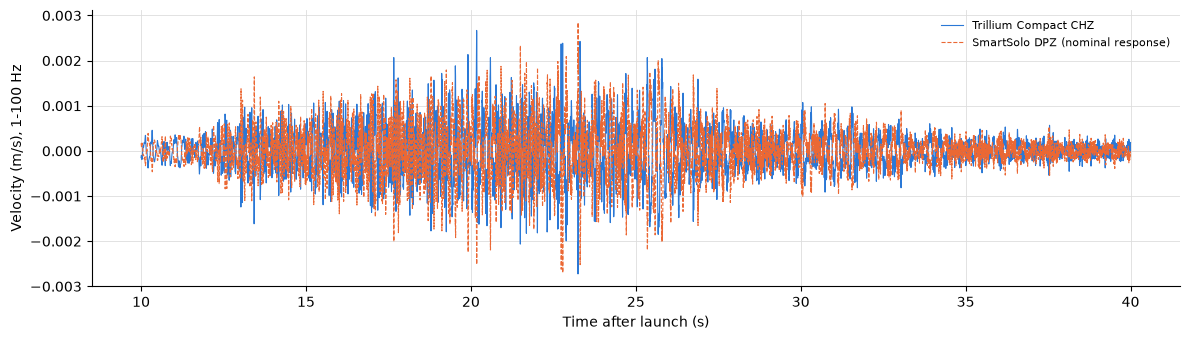

In [9]:
# SmartSolo to velocity with the nominal geophone, then compare in a common band.
paz = sensor_paz(g['f0'], g['damping'])
paz['sensitivity'] = g['sensitivity_mV_per_mps']
sv = ss.copy()
sv.simulate(paz_remove=paz, paz_simulate=None, remove_sensitivity=True,
            pre_filt=(0.5, 1.0, 200.0, 230.0), taper=True)
pair = Stream([tz.copy(), sv])
pair.filter('bandpass', freqmin=1.0, freqmax=100.0, corners=4, zerophase=True)
a, b = (t.slice(*SIGNAL).data.astype(float) for t in pair)
n = min(len(a), len(b)); a, b = a[:n], b[:n]
r = np.corrcoef(a, b)[0, 1]
print(f'1-100 Hz: peak Trillium {np.abs(a).max():.3g} m/s, SmartSolo {np.abs(b).max():.3g} m/s, '
      f'ratio {np.abs(b).max() / np.abs(a).max():.2f}; zero-lag correlation {r:+.3f}')

fig, ax = plt.subplots(figsize=(12, 3.5))
t0 = pair[0].slice(L + 10, L + 40); t1 = pair[1].slice(L + 10, L + 40)
ax.plot(t0.times() + 10, t0.data, color='#2a78d6', lw=0.8, label='Trillium Compact CHZ')
ax.plot(t1.times() + 10, t1.data, color='#eb6834', lw=0.8, ls='--', label='SmartSolo DPZ (nominal response)')
ax.set(xlabel='Time after launch (s)', ylabel='Velocity (m/s), 1-100 Hz')
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(OUT / 'smartsolo_vs_trillium_B01_waveforms.png', dpi=200)

## Caveats

* **B05 CHZ** (and CH1) drift through ~±1 mm/s over minutes, starting *before* launch: an instrument
  transient, not ground motion. Its low-frequency fractions are artifacts; use B01 and B29 for the
  seismic conclusions.
* **B01 CHZ** shows excess power below ~0.2 Hz during the launch (≈5% of its excess energy), absent at
  B29. A broadband sensor 1.5 km from the pad is sensitive to tilt from acoustic loading, so this may
  be tilt rather than translational ground motion; it is real launch-induced energy either way.
* **infraBSU above ~100 Hz** relies on the nominal single-pole sensor model; the sensor's high-frequency
  roll-off is not in the response, so infrasound fractions above 100 Hz are approximate.
* **Gem overflow** (notebook 30) does not affect this notebook, which uses Centaur channels only.
* Effective bandwidth after a digitizer's anti-alias filter is ~0.8 × Nyquist; both the strict-Nyquist
  and the 0.8 × Nyquist fractions are tabulated.